
## 1. Import Libraries


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.seasonal import seasonal_decompose

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")



2. Load the Dataset and Prepare the Datetime

The dataset contains hourly electricity demand measured in megawatts (MW). We convert `Datetime` into a proper datetime format, sort the observations chronologically, remove duplicate timestamps, and check for missing values.


In [2]:

file_path = "c:/Users/Alexa/Downloads/PJME_hourly.csv"

df = pd.read_csv(file_path)

print("Original shape:", df.shape)
print("Columns:", df.columns.tolist())

required_columns = {"Datetime", "PJME_MW"}
missing_columns = required_columns - set(df.columns)

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

df["Datetime"] = pd.to_datetime(df["Datetime"], errors="coerce")
df["PJME_MW"] = pd.to_numeric(df["PJME_MW"], errors="coerce")

print("\nMissing values before cleaning:")
print(df.isna().sum())

df = df.dropna(subset=["Datetime", "PJME_MW"]).copy()

duplicate_count = df["Datetime"].duplicated().sum()
print("\nDuplicate timestamps before removal:", duplicate_count)

# Average duplicated timestamps so that every timestamp has one value.
df = (
    df.groupby("Datetime", as_index=False)["PJME_MW"]
      .mean()
      .sort_values("Datetime")
      .reset_index(drop=True)
)

print("\nCleaned shape:", df.shape)
print("Start:", df["Datetime"].min())
print("End:", df["Datetime"].max())

print("\nMissing values after cleaning:")
print(df.isna().sum())

df.head()


Original shape: (145366, 2)
Columns: ['Datetime', 'PJME_MW']

Missing values before cleaning:
Datetime    0
PJME_MW     0
dtype: int64

Duplicate timestamps before removal: 4

Cleaned shape: (145362, 2)
Start: 2002-01-01 01:00:00
End: 2018-08-03 00:00:00

Missing values after cleaning:
Datetime    0
PJME_MW     0
dtype: int64


,Datetime,PJME_MW
0,2002-01-01 01:00:00,30393.0
1,2002-01-01 02:00:00,29265.0
2,2002-01-01 03:00:00,28357.0
3,2002-01-01 04:00:00,27899.0
4,2002-01-01 05:00:00,28057.0



Interpretation

The dataset is an hourly time series because each observation is associated with a timestamp. The datetime field is converted to a proper datetime type and the observations are arranged chronologically. Duplicate timestamps are handled so that each timestamp has one electricity-demand value.

Insight

Correct datetime handling is important because the later analyses depend on hour, day, month, and year. Cleaning duplicate timestamps also prevents repeated observations from giving extra weight to particular time periods.

Recommended Action

Use the cleaned chronological dataset as the basis for visualization, seasonal analysis, and decomposition.



STEP 1 – Descriptive Statistics


In [3]:

print("Descriptive statistics:")
display(df["PJME_MW"].describe())

mean_value = df["PJME_MW"].mean()
median_value = df["PJME_MW"].median()
std_value = df["PJME_MW"].std()
min_value = df["PJME_MW"].min()
max_value = df["PJME_MW"].max()

print(f"Mean: {mean_value:,.2f} MW")
print(f"Median: {median_value:,.2f} MW")
print(f"Standard deviation: {std_value:,.2f} MW")
print(f"Minimum: {min_value:,.2f} MW")
print(f"Maximum: {max_value:,.2f} MW")
print(f"Range: {max_value - min_value:,.2f} MW")

q1 = df["PJME_MW"].quantile(0.25)
q3 = df["PJME_MW"].quantile(0.75)
iqr = q3 - q1

lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

outliers = df[(df["PJME_MW"] < lower_fence) | (df["PJME_MW"] > upper_fence)]

print(f"\nQ1: {q1:,.2f} MW")
print(f"Q3: {q3:,.2f} MW")
print(f"IQR: {iqr:,.2f} MW")
print(f"Lower outlier fence: {lower_fence:,.2f} MW")
print(f"Upper outlier fence: {upper_fence:,.2f} MW")
print(f"Potential outliers using the 1.5×IQR rule: {len(outliers):,}")

print("\nTimestamp of minimum:")
print(df.loc[df["PJME_MW"].idxmin(), ["Datetime", "PJME_MW"]])

print("\nTimestamp of maximum:")
print(df.loc[df["PJME_MW"].idxmax(), ["Datetime", "PJME_MW"]])


Descriptive statistics:


count    145362.000000
mean      32080.507722
std        6463.870519
min       14544.000000
25%       27573.000000
50%       31421.000000
75%       35650.000000
max       62009.000000
Name: PJME_MW, dtype: float64

Mean: 32,080.51 MW
Median: 31,421.00 MW
Standard deviation: 6,463.87 MW
Minimum: 14,544.00 MW
Maximum: 62,009.00 MW
Range: 47,465.00 MW

Q1: 27,573.00 MW
Q3: 35,650.00 MW
IQR: 8,077.00 MW
Lower outlier fence: 15,457.50 MW
Upper outlier fence: 47,765.50 MW
Potential outliers using the 1.5×IQR rule: 3,455

Timestamp of minimum:
Datetime    2012-10-30 04:00:00
PJME_MW                 14544.0
Name: 94901, dtype: object

Timestamp of maximum:
Datetime    2006-08-02 17:00:00
PJME_MW                 62009.0
Name: 40183, dtype: object



Interpretation

The descriptive statistics show the typical level and variability of hourly electricity demand. The mean and median describe the center of the distribution, while the standard deviation and range show how widely demand varies. The minimum and maximum values identify unusually low and high demand periods.

Insight

The large difference between low and high demand indicates that electricity use changes substantially depending on time and operating conditions. Potential outliers should not automatically be deleted because extreme electricity demand can represent real peak-demand events.

Decision / Recommended Action

Peak and unusually low observations should be investigated before being removed. If they are valid demand events, they should be retained and considered when planning capacity and forecasting models.



STEP 2 – Time Plot


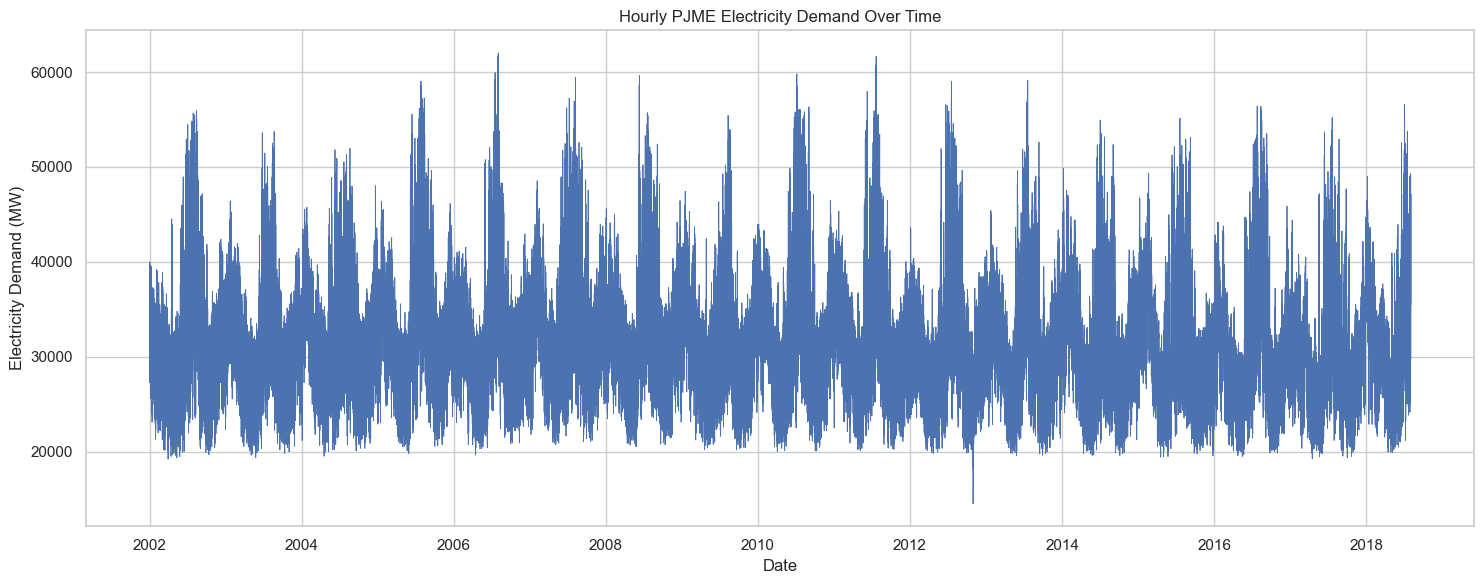

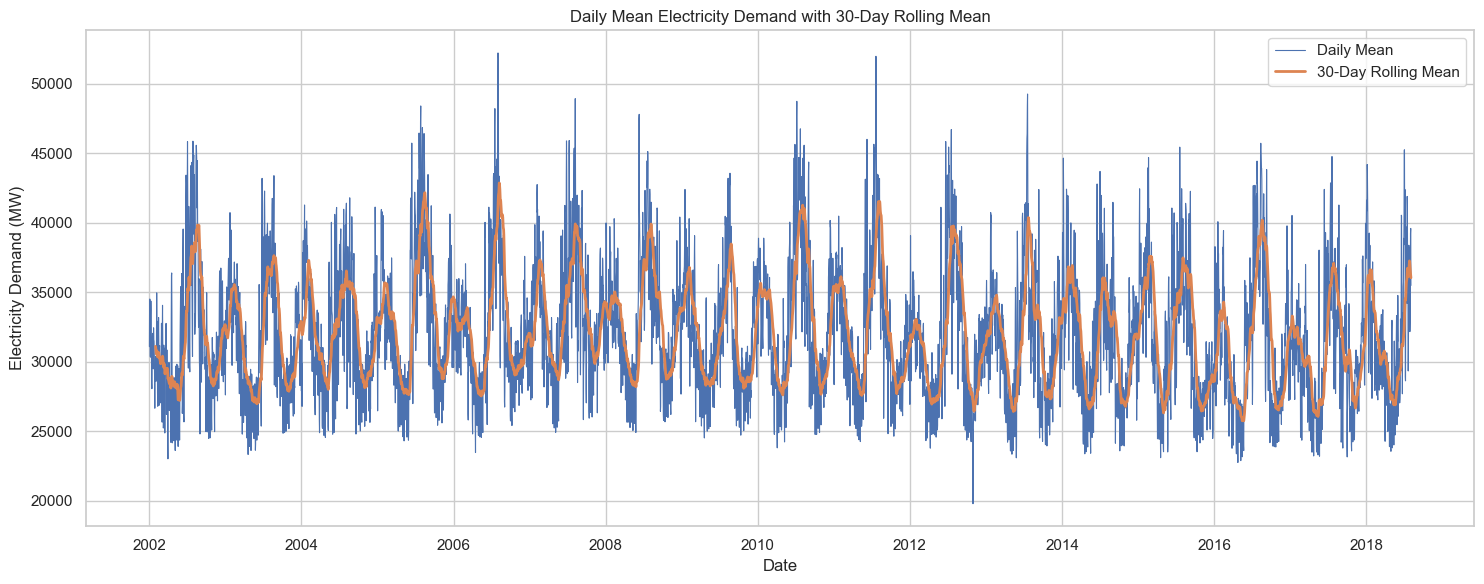

Highest observed demand: 62,009 MW on 2006-08-02 17:00:00
Lowest observed demand: 14,544 MW on 2012-10-30 04:00:00


In [4]:

ts = df.set_index("Datetime")["PJME_MW"]

plt.figure(figsize=(15, 6))
plt.plot(ts.index, ts.values, linewidth=0.6)
plt.title("Hourly PJME Electricity Demand Over Time")
plt.xlabel("Date")
plt.ylabel("Electricity Demand (MW)")
plt.tight_layout()
plt.show()

# A smoother view makes the long-term trend easier to see.
daily_mean = ts.resample("D").mean()

plt.figure(figsize=(15, 6))
plt.plot(daily_mean.index, daily_mean.values, linewidth=0.8, label="Daily Mean")
plt.plot(daily_mean.rolling(30).mean(), linewidth=2, label="30-Day Rolling Mean")
plt.title("Daily Mean Electricity Demand with 30-Day Rolling Mean")
plt.xlabel("Date")
plt.ylabel("Electricity Demand (MW)")
plt.legend()
plt.tight_layout()
plt.show()

peak_row = df.loc[df["PJME_MW"].idxmax()]
low_row = df.loc[df["PJME_MW"].idxmin()]

print(f"Highest observed demand: {peak_row['PJME_MW']:,.0f} MW on {peak_row['Datetime']}")
print(f"Lowest observed demand: {low_row['PJME_MW']:,.0f} MW on {low_row['Datetime']}")



Interpretation

The time plot shows strong short-term fluctuations in electricity demand together with recurring seasonal behavior. The rolling mean reduces hourly noise and makes longer-term changes easier to observe.

Insight

Electricity demand is not constant. It follows repeated patterns over time, which suggests that hour-of-day, day-of-week, and seasonal information can be useful predictors for forecasting.

Decision / Recommended Action

Forecasting models should include time-based features and seasonal components. Energy planners should pay particular attention to recurring high-demand periods.



STEP 3 – Seasonal Plots


3.1 Monthly / Yearly Trend

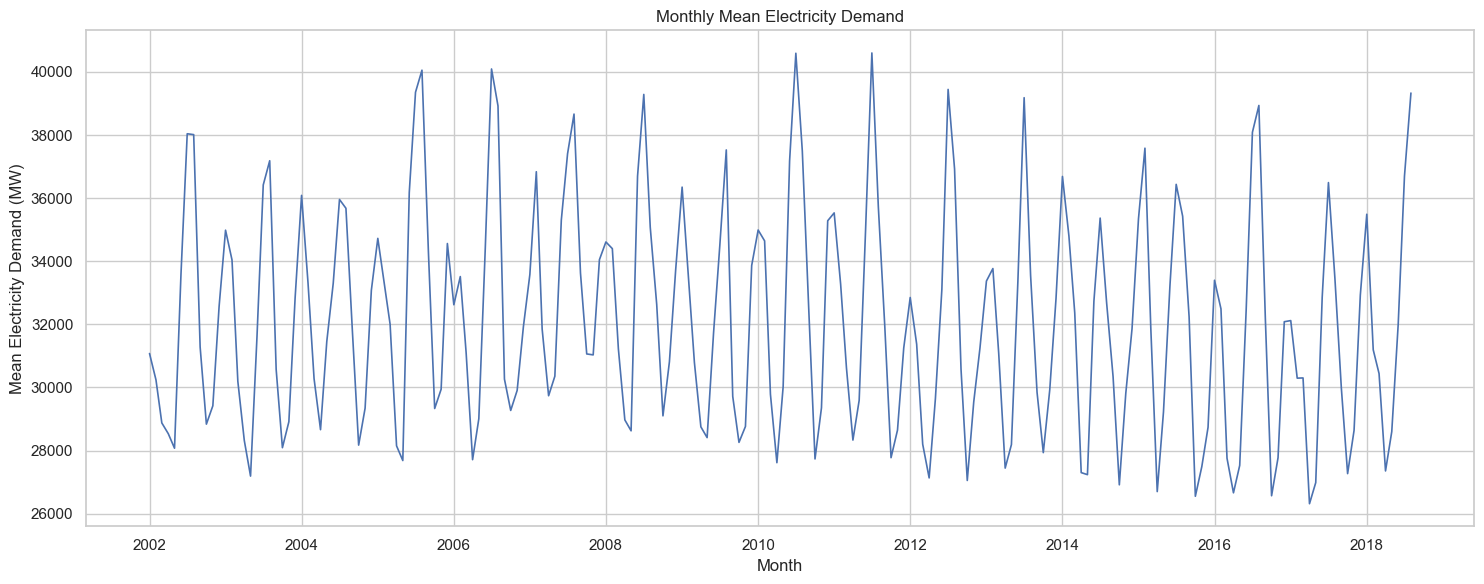

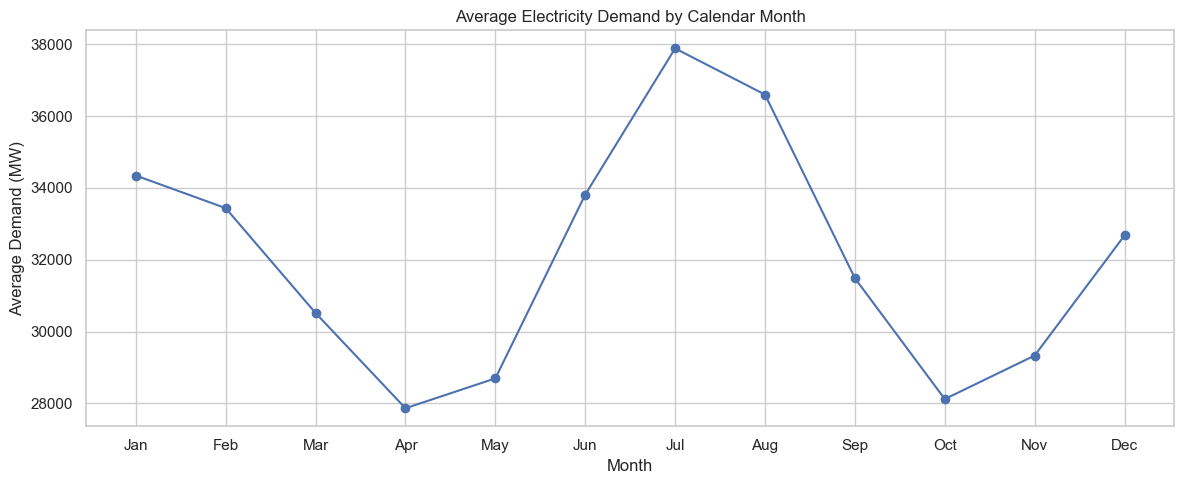

Highest average calendar month: Jul
Lowest average calendar month: Apr


In [5]:

monthly_mean = ts.resample("MS").mean()

plt.figure(figsize=(15, 6))
plt.plot(monthly_mean.index, monthly_mean.values, linewidth=1.2)
plt.title("Monthly Mean Electricity Demand")
plt.xlabel("Month")
plt.ylabel("Mean Electricity Demand (MW)")
plt.tight_layout()
plt.show()

# Average demand by calendar month across all years
calendar_month_mean = df.assign(
    Month=df["Datetime"].dt.month
).groupby("Month")["PJME_MW"].mean()

month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
               "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

plt.figure(figsize=(12, 5))
plt.plot(month_names, calendar_month_mean.values, marker="o")
plt.title("Average Electricity Demand by Calendar Month")
plt.xlabel("Month")
plt.ylabel("Average Demand (MW)")
plt.tight_layout()
plt.show()

highest_month = calendar_month_mean.idxmax()
lowest_month = calendar_month_mean.idxmin()

print(f"Highest average calendar month: {month_names[highest_month-1]}")
print(f"Lowest average calendar month: {month_names[lowest_month-1]}")



Interpretation

The monthly plots show that electricity demand changes across the year rather than remaining constant. The calendar-month comparison identifies which months typically have higher and lower average demand.

Insight

The repeated monthly pattern indicates annual seasonality. Energy use can be affected by weather and human activity, so demand levels can differ substantially between seasons.

Recommended Action

Use month and other seasonal variables in forecasting models. Energy planning should prepare for the recurring high-demand months instead of relying only on an overall average.


3.2 Weekly Pattern

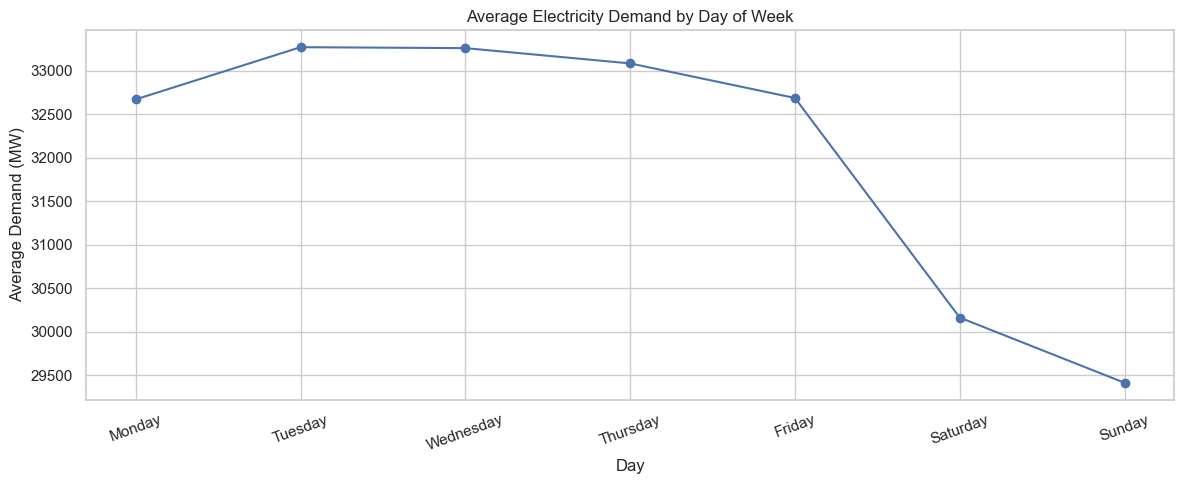

Highest average day: Tuesday
Lowest average day: Sunday


In [6]:

df["DayOfWeek"] = df["Datetime"].dt.dayofweek

weekday_mean = (
    df.groupby("DayOfWeek")["PJME_MW"]
      .mean()
      .reindex(range(7))
)

day_names = ["Monday", "Tuesday", "Wednesday", "Thursday",
             "Friday", "Saturday", "Sunday"]

plt.figure(figsize=(12, 5))
plt.plot(day_names, weekday_mean.values, marker="o")
plt.title("Average Electricity Demand by Day of Week")
plt.xlabel("Day")
plt.ylabel("Average Demand (MW)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

highest_day = weekday_mean.idxmax()
lowest_day = weekday_mean.idxmin()

print(f"Highest average day: {day_names[highest_day]}")
print(f"Lowest average day: {day_names[lowest_day]}")



Interpretation

The weekly pattern compares average electricity demand from Monday through Sunday. Differences between weekdays and weekends indicate a recurring weekly seasonal effect.

Insight

Demand often changes when normal work and business schedules change. A clear weekday-weekend difference means weekly seasonality should be considered in forecasting.

Recommended Action

Include day-of-week and weekend indicators in forecasting models and use them when scheduling generation or other energy resources.


## 3.3 Daily Hourly M-Profile

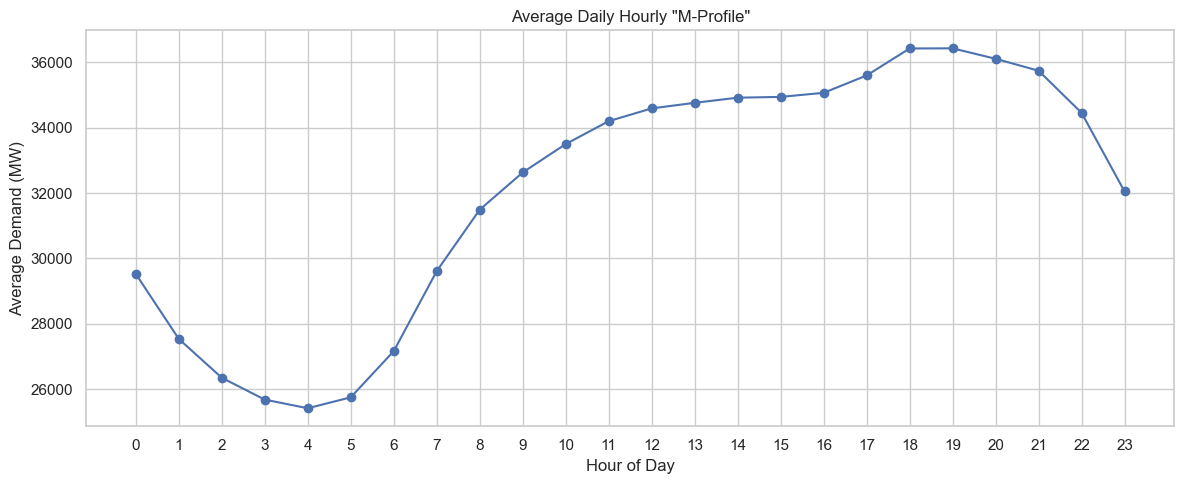

Highest average hour: 19:00
Lowest average hour: 04:00


In [7]:

df["Hour"] = df["Datetime"].dt.hour

hourly_mean = df.groupby("Hour")["PJME_MW"].mean()

plt.figure(figsize=(12, 5))
plt.plot(hourly_mean.index, hourly_mean.values, marker="o")
plt.title('Average Daily Hourly "M-Profile"')
plt.xlabel("Hour of Day")
plt.ylabel("Average Demand (MW)")
plt.xticks(range(24))
plt.tight_layout()
plt.show()

peak_hour = hourly_mean.idxmax()
lowest_hour = hourly_mean.idxmin()

print(f"Highest average hour: {peak_hour:02d}:00")
print(f"Lowest average hour: {lowest_hour:02d}:00")



Interpretation

The hourly M-profile shows how electricity demand changes within a typical 24-hour day. Demand is generally lower during overnight hours and rises during active daytime and evening periods.

Insight

The daily cycle is one of the strongest repeating patterns in hourly electricity data. The peak hour indicates when demand pressure is greatest, while the lowest hour indicates the period of relatively low demand.

Recommended Action

Use hour-of-day features in forecasting. Energy resources can be scheduled ahead of recurring peak hours, while maintenance or lower-priority activities can be planned during lower-demand periods when appropriate.



STEP 4 – Box Plots


4.1 Total Distribution

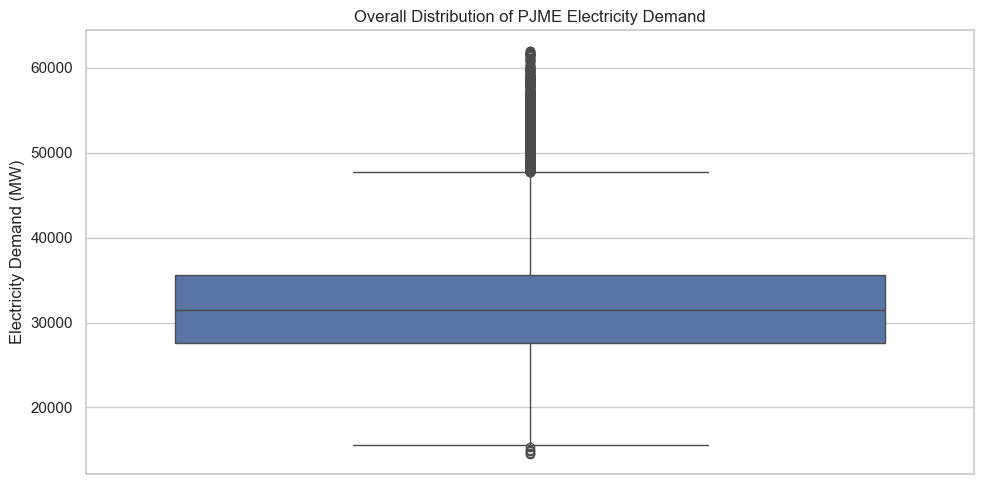

In [8]:

plt.figure(figsize=(10, 5))
sns.boxplot(y=df["PJME_MW"])
plt.title("Overall Distribution of PJME Electricity Demand")
plt.ylabel("Electricity Demand (MW)")
plt.tight_layout()
plt.show()



Interpretation

The overall box plot shows the median, middle 50% of observations, spread, and potential extreme values. Points beyond the whiskers are potential statistical outliers.

Insight

Extreme observations indicate that demand sometimes moves far away from its typical level. These observations can be important because peak demand may represent real operational conditions.

Recommended Action

Investigate extreme observations before removing them. Valid peaks should be retained because they are useful for capacity planning and forecasting.


4.2 Year-Month / Monthly Dispersion

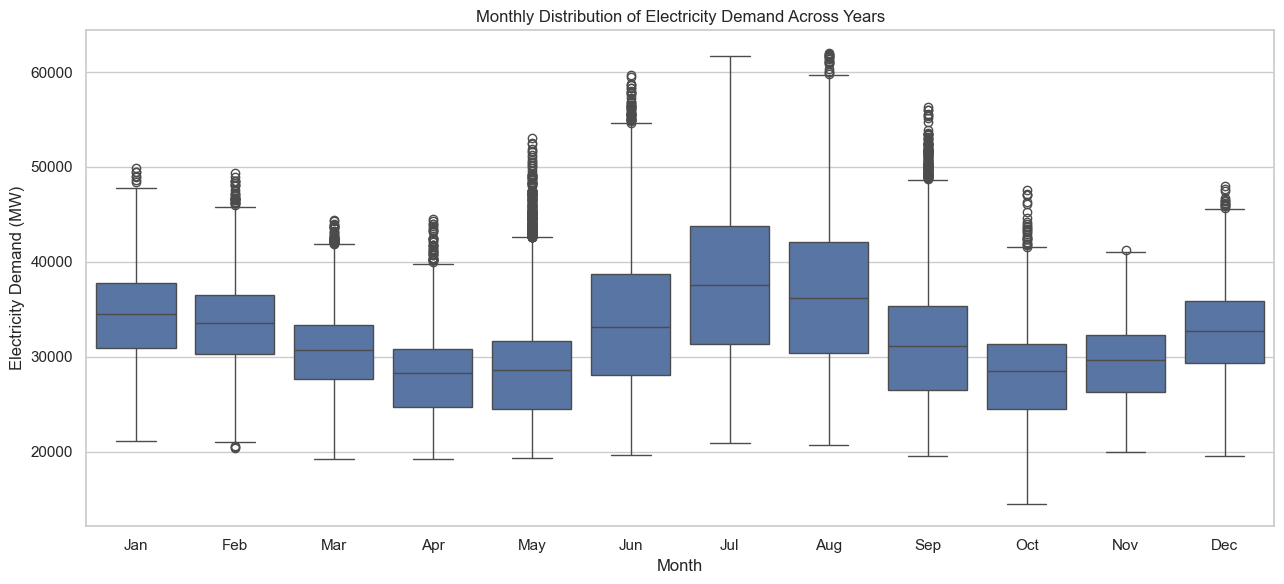

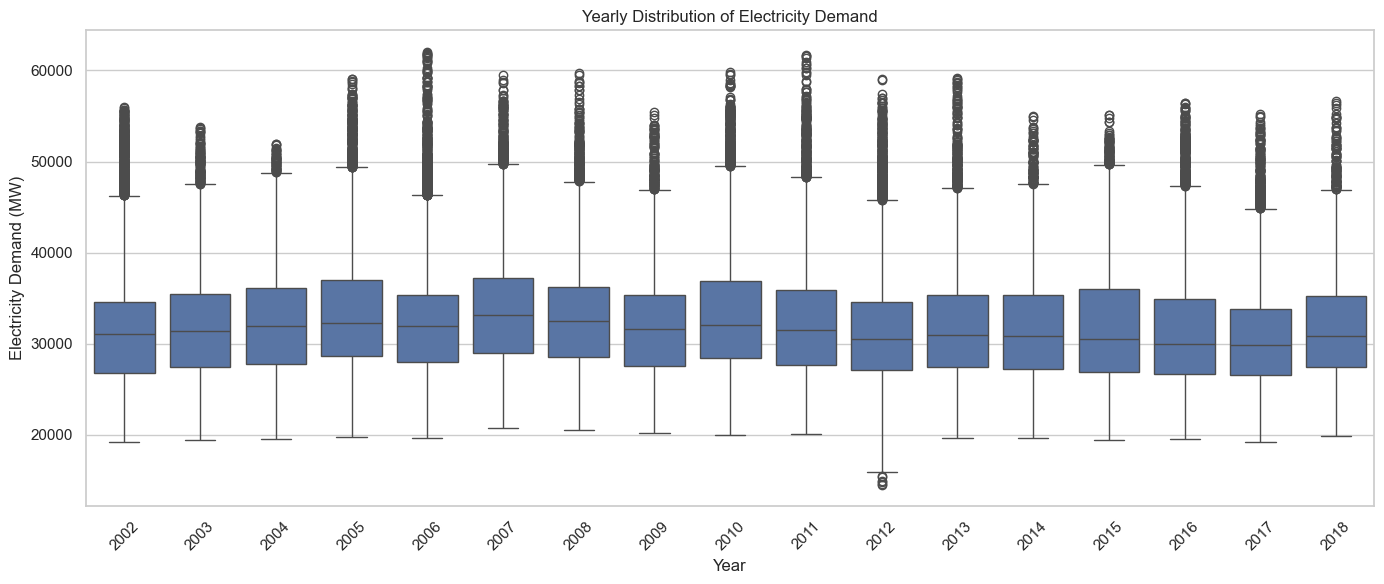

In [9]:

plot_df = df.copy()
plot_df["MonthName"] = plot_df["Datetime"].dt.month.map(
    dict(enumerate(month_names, start=1))
)

plt.figure(figsize=(13, 6))
sns.boxplot(data=plot_df, x="MonthName", y="PJME_MW")
plt.title("Monthly Distribution of Electricity Demand Across Years")
plt.xlabel("Month")
plt.ylabel("Electricity Demand (MW)")
plt.tight_layout()
plt.show()

# Yearly dispersion is also shown because it is useful for checking long-term changes.
plot_df["Year"] = plot_df["Datetime"].dt.year

plt.figure(figsize=(14, 6))
sns.boxplot(data=plot_df, x="Year", y="PJME_MW")
plt.title("Yearly Distribution of Electricity Demand")
plt.xlabel("Year")
plt.ylabel("Electricity Demand (MW)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



Interpretation

The monthly box plot compares the distribution and variability of demand across calendar months. The yearly box plot shows whether the typical level and spread of demand changed over the years.

Insight

Different months can have different centers and spreads, confirming seasonal behavior. Differences between years may also indicate changes in the overall demand level or variability.

Recommended Action

Monthly and yearly patterns should be considered when planning energy resources and building forecasting models. The model should not assume that every month has the same demand distribution.


4.3 Hourly Distribution

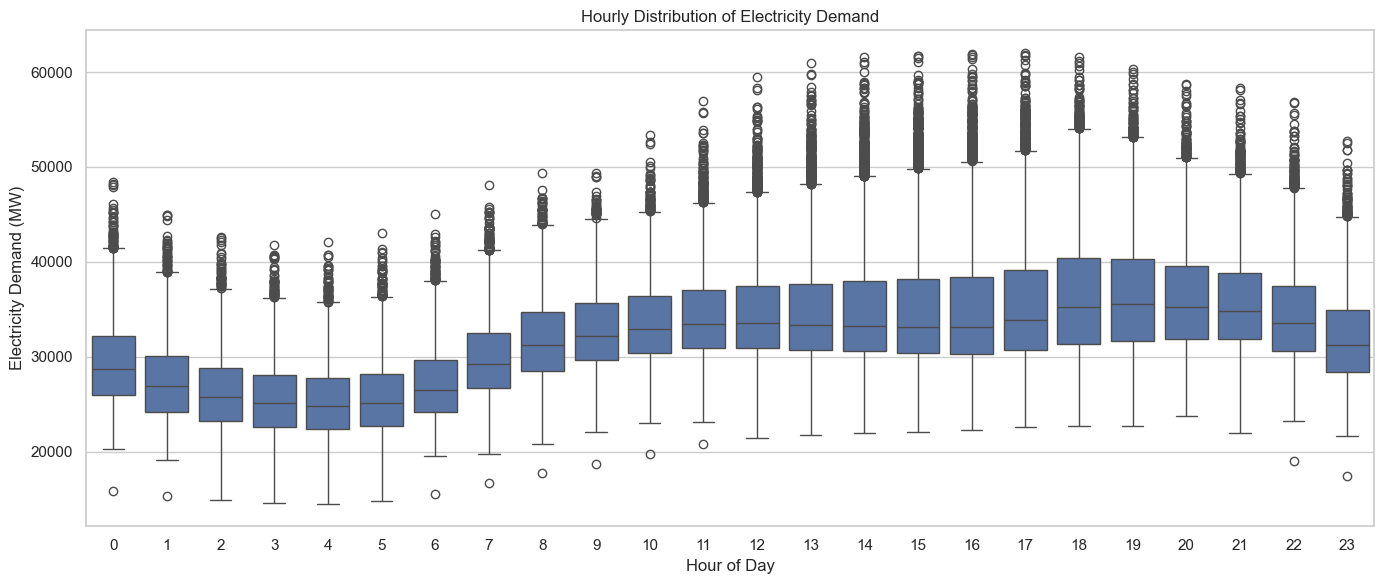

In [10]:

plt.figure(figsize=(14, 6))
sns.boxplot(data=df, x="Hour", y="PJME_MW")
plt.title("Hourly Distribution of Electricity Demand")
plt.xlabel("Hour of Day")
plt.ylabel("Electricity Demand (MW)")
plt.tight_layout()
plt.show()



### Interpretation

The hourly box plot shows how the center and variability of electricity demand differ by hour. Some hours have higher medians and wider distributions than others.

### Insight

The hour of day is an important source of predictable variation. Wider boxes or longer whiskers indicate greater variability during particular hours.

### Recommended Action

Use hourly patterns when estimating peak demand and when creating forecasting features. High-variability hours deserve closer monitoring because forecasts may be less certain during those periods.


STEP 5 – Time-Series Decomposition

Decomposition separates a time series into:
- Observed
- Trend
- Seasonal
- Residual

Two common models are:
- Additive: Observed = Trend + Seasonal + Residual
- Multiplicative: Observed = Trend × Seasonal × Residual

For the full-year seasonal pattern, the hourly data are first converted to daily mean demand. A 365-day period is then used. For monthly seasonality, monthly mean demand is used with a 12-month period.


5.1 Additive Decomposition – Full-Year Seasonal Pattern

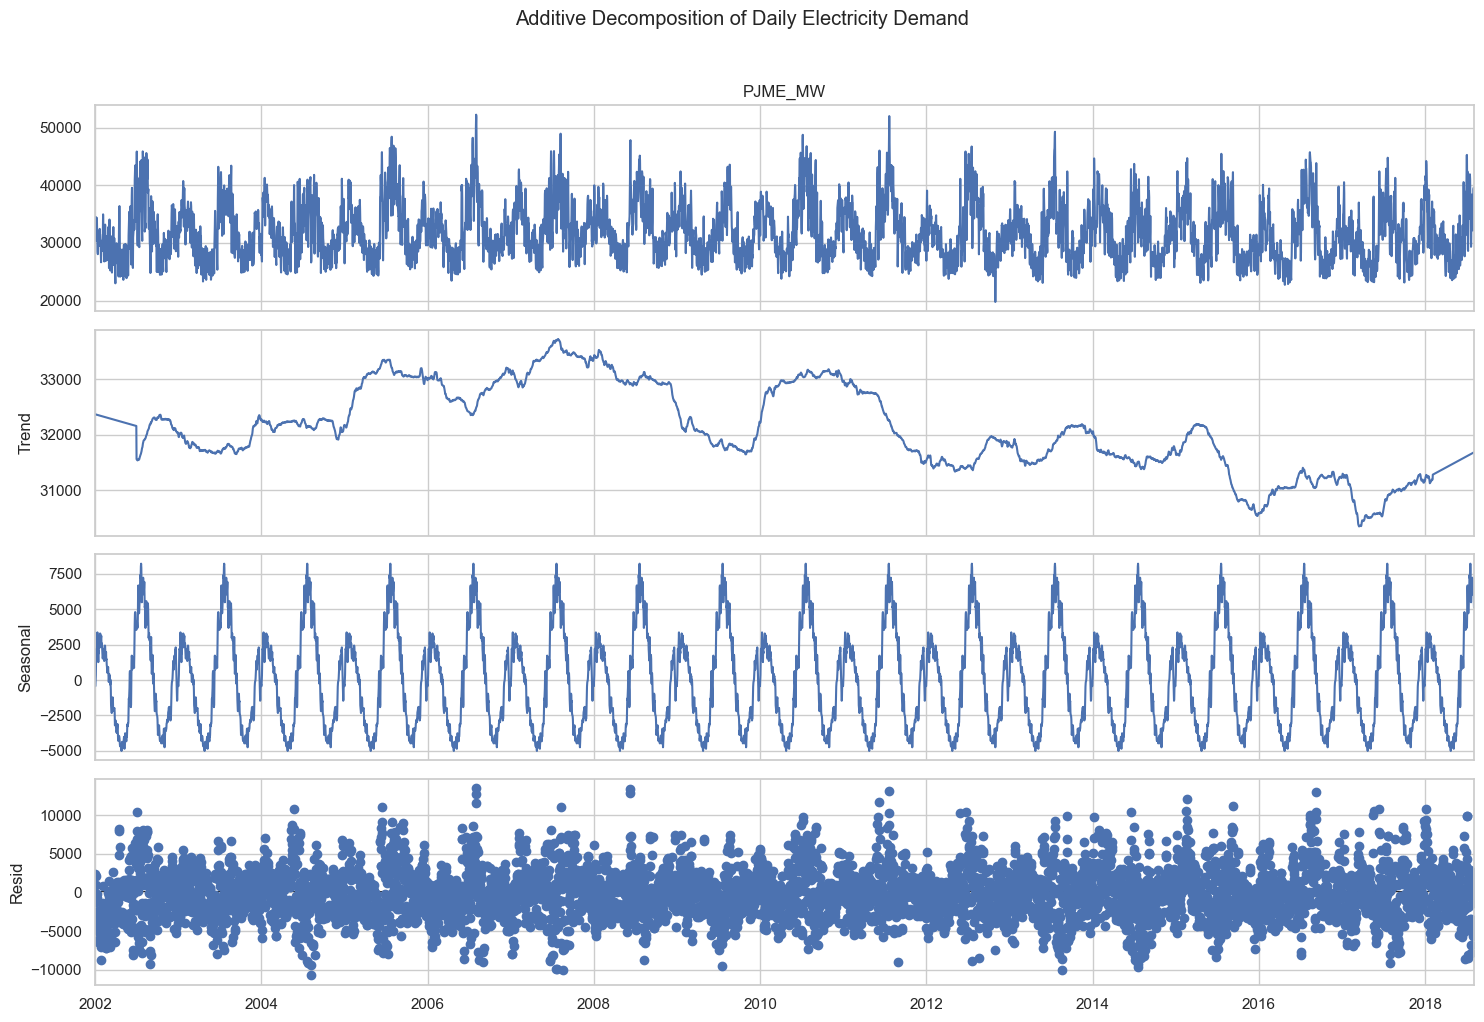

In [11]:

daily = ts.resample("D").mean().interpolate()

additive_daily = seasonal_decompose(
    daily,
    model="additive",
    period=365,
    extrapolate_trend="freq"
)

fig = additive_daily.plot()
fig.set_size_inches(15, 10)
fig.suptitle("Additive Decomposition of Daily Electricity Demand", y=1.02)
plt.tight_layout()
plt.show()



Interpretation

The additive decomposition separates the daily demand series into long-term trend, repeating yearly seasonal movement, and residual variation. The seasonal component shows recurring annual behavior, while the residual represents variation not explained by the trend and seasonal components.

Insight

A strong seasonal component indicates that annual demand patterns are systematic rather than random. The residual component can help identify unusual observations or short-term events.

Recommended Action

Use the trend and seasonal components to improve forecasting and capacity planning. Residuals should also be examined for unusual events that may require additional explanatory variables.


5.2 Multiplicative Decomposition – Full-Year Seasonal Pattern

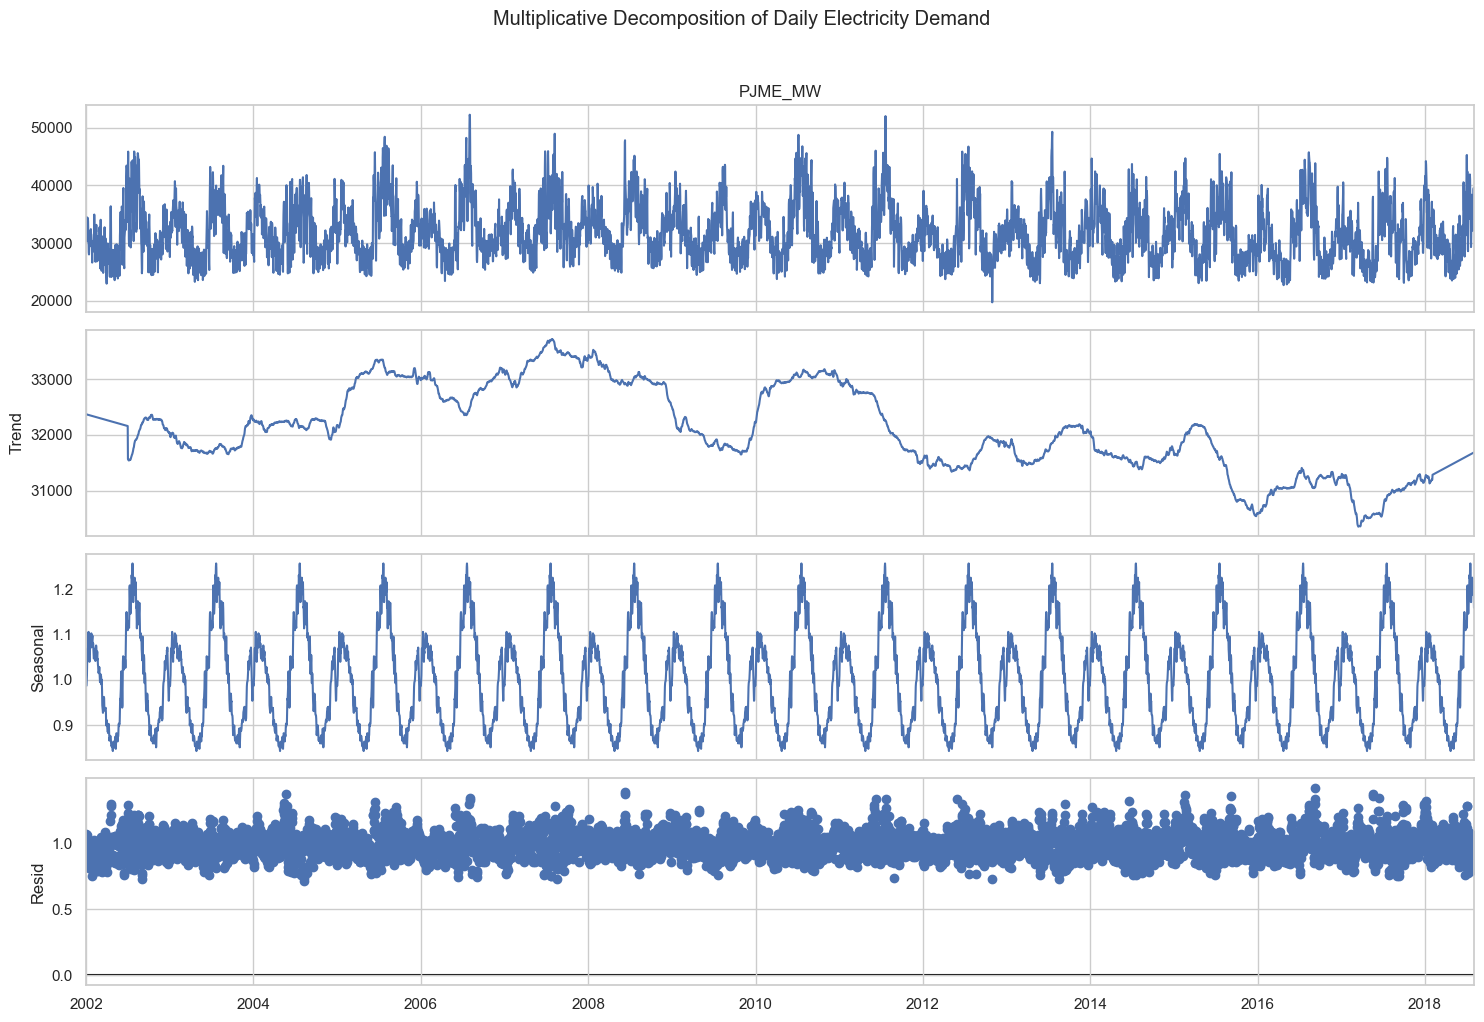

In [12]:

multiplicative_daily = seasonal_decompose(
    daily,
    model="multiplicative",
    period=365,
    extrapolate_trend="freq"
)

fig = multiplicative_daily.plot()
fig.set_size_inches(15, 10)
fig.suptitle("Multiplicative Decomposition of Daily Electricity Demand", y=1.02)
plt.tight_layout()
plt.show()



Interpretation

The multiplicative decomposition expresses seasonal effects as proportions of the trend. It is useful when the size of seasonal fluctuations changes as the overall level of the series changes.

Insight

If the seasonal swings become larger when the overall demand level is higher, the multiplicative model can describe the series more naturally than an additive model.

Recommended Action

Compare the additive and multiplicative components and choose the structure that best represents the observed behavior when building a forecasting model.


5.3 Additive Decomposition – Monthly Series

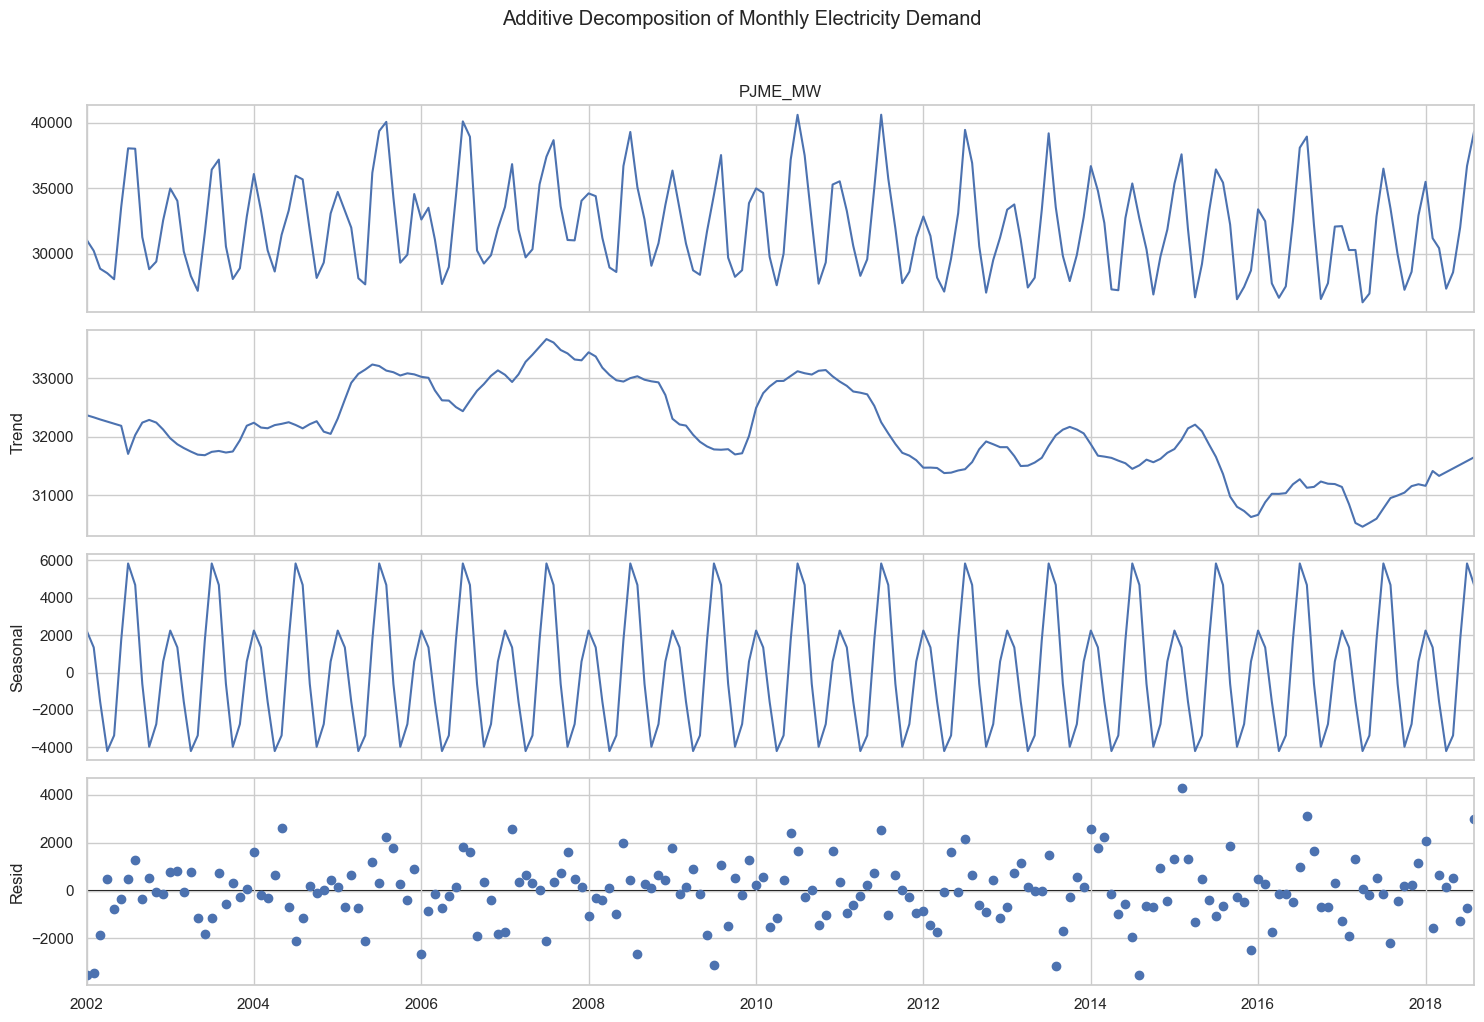

In [13]:

monthly = ts.resample("MS").mean().interpolate()

additive_monthly = seasonal_decompose(
    monthly,
    model="additive",
    period=12,
    extrapolate_trend="freq"
)

fig = additive_monthly.plot()
fig.set_size_inches(15, 10)
fig.suptitle("Additive Decomposition of Monthly Electricity Demand", y=1.02)
plt.tight_layout()
plt.show()


5.4 Multiplicative Decomposition – Monthly Series

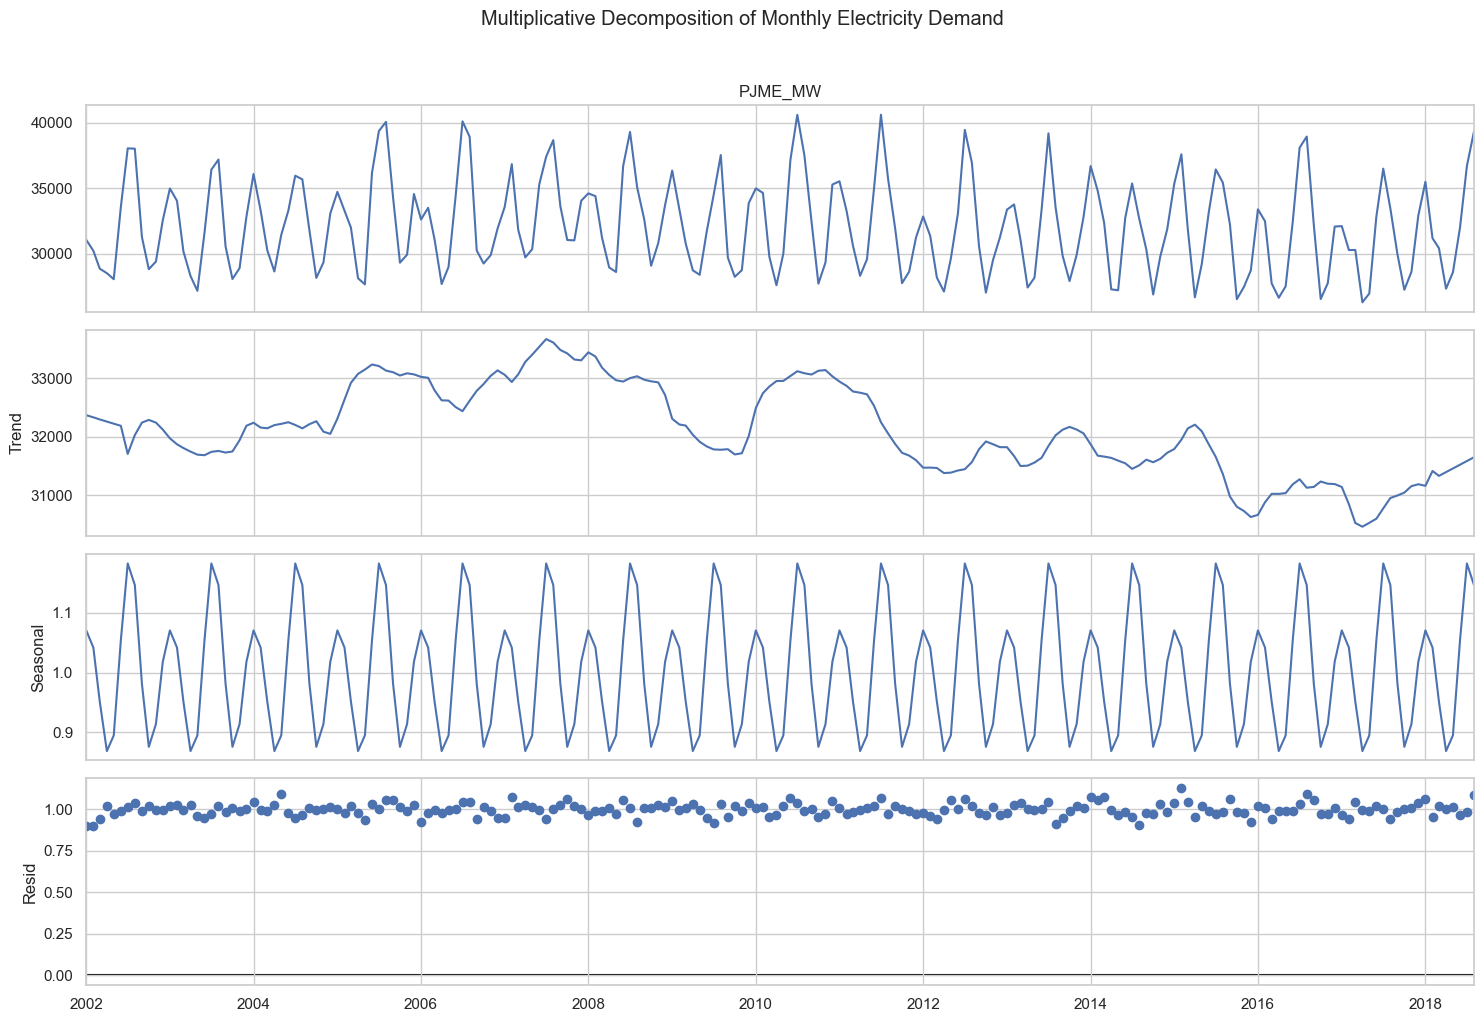

In [14]:

multiplicative_monthly = seasonal_decompose(
    monthly,
    model="multiplicative",
    period=12,
    extrapolate_trend="freq"
)

fig = multiplicative_monthly.plot()
fig.set_size_inches(15, 10)
fig.suptitle("Multiplicative Decomposition of Monthly Electricity Demand", y=1.02)
plt.tight_layout()
plt.show()



Decomposition Interpretation

The decomposition confirms that the electricity-demand series contains multiple time-based components. The trend describes longer-term movement, while the seasonal component captures recurring patterns. The residual component contains irregular variation that is not explained by trend and seasonality.

Additive vs. Multiplicative

The additive model is more appropriate when seasonal changes are roughly constant in size over time. The multiplicative model is more appropriate when seasonal changes increase or decrease with the overall level of demand.

For this dataset, the final choice should be based on which decomposition produces the more stable and realistic residual behavior and better represents the changing seasonal amplitude.


Key Behavioral Patterns

The PJME hourly electricity-demand series shows clear time-dependent behavior. Demand changes by hour of day, day of week, and month of the year. The time plot and seasonal plots reveal recurring patterns rather than purely random movement. Box plots also show differences in the distribution and variability of demand across months, years, and hours.

Operational Implications

The recurring peak periods are important for electricity resource planning. Knowing when demand is usually high can help energy managers prepare sufficient generation and avoid shortages. Lower-demand periods can also be used for suitable maintenance and resource scheduling.

How Exploratory Time-Series Analysis Improves Forecasting

Exploratory time-series analysis identifies trend, daily seasonality, weekly seasonality, annual seasonality, variability, and potential anomalies before a forecasting model is built. These findings help select useful time-based features and appropriate seasonal forecasting methods.

Overall Recommendation

A forecasting system for PJME electricity demand should consider:
- hour of day
- day of week
- month or season
- long-term trend
- recent demand values
- peak-demand behavior
- unusual observations

These features can improve forecasting and support better energy-management decisions.
